# Assignment Problems: Day 11

The following problems require access to the file named ‘Dataset_Day11.csv’, provided with this assignment. (Use Random State = 99)

This is the same assignment data as Day 10.

The datasets include data from 768 women with several medical predictor variables and one target variable(‘Outcome’). The classification goal is to predict whether or not the patients in the dataset have diabetes or not.
 
For columns: Glucose, BloodPressure, BMI, DiabetesPedigreeFunction

If the column value is 0, then they should be considered as missing data.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import svm
from sklearn import tree
from math import log, sqrt
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, log_loss, precision_recall_curve, accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, AdaBoostClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

* Firstly, replace all Missing values with relevant figures.
* Then remove all existing outliers and get the final data for classification.

In [2]:
data = pd.read_csv("Dataset_Day7.csv")

# Missing data treatment
print('Before Missing Data Treatment')
for col in ['Glucose', 'BloodPressure', 'BMI', 'DiabetesPedigreeFunction'] :
    print(col,' = ',len(data[col][data[col]==0]))
for col in ['Glucose', 'BloodPressure', 'BMI', 'DiabetesPedigreeFunction'] :
    data[col][data[col]==0] = data[col].median()
print('\nAfter Missing Data Treatment')
for col in ['Glucose', 'BloodPressure', 'BMI', 'DiabetesPedigreeFunction'] :
    print(col,' = ',len(data[col][data[col]==0]))

outlier = pd.DataFrame(columns = ["Pregnancies","Glucose","BloodPressure","BMI","Age"])
temp = data.drop('Outcome',axis=1)
for col in ["Pregnancies","Glucose","BloodPressure","BMI","Age"]:
    Q1 = temp[col].quantile(0.25)
    Q3 = temp[col].quantile(0.75)
    IQR = Q3 - Q1
    UpperBound = Q3 + 1.5*IQR
    LowerBound = Q1 - 1.5*IQR
    outlier[col] = temp[col][(temp[col]<=LowerBound)|(temp[col]>=UpperBound)]

OutlierFreeData = data.drop(outlier.index,axis=0)
print("\nno. of Outlier",len(outlier), "\n% of Outlier = ", str(len(outlier)/len(data)*100))

Before Missing Data Treatment
Glucose  =  5
BloodPressure  =  35
BMI  =  11
DiabetesPedigreeFunction  =  0

After Missing Data Treatment
Glucose  =  0
BloodPressure  =  0
BMI  =  0
DiabetesPedigreeFunction  =  0

no. of Outlier 4 
% of Outlier =  0.5208333333333333


C:\Users\nikhi\AppData\Local\Temp\ipykernel_4264\3315839205.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col][data[col]==0] = data[col].median()


* Split the data into 80% training and 20% testing data. Use target variable as ‘Outcome’.

In [3]:
# Spliting of data 7:3
X = OutlierFreeData.drop("Outcome",axis=1)
y = OutlierFreeData["Outcome"]
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.20, random_state=4)

Model Performance metrics are as below :-

Accuracy is  0.8366013071895425
Precision is  0.7592592592592593
Recall is  0.7735849056603774
F1-Score is  0.7663551401869159
[[87 13]
 [12 41]]


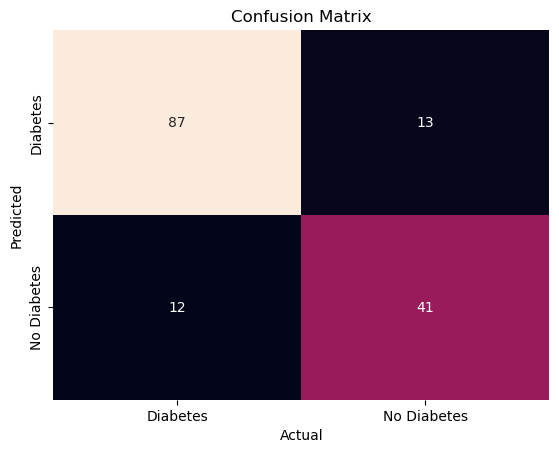

|--- feature_1 <= 127.50
|   |--- feature_5 <= 28.50
|   |   |--- class: 0
|   |--- feature_5 >  28.50
|   |   |--- feature_3 <= 26.35
|   |   |   |--- class: 0
|   |   |--- feature_3 >  26.35
|   |   |   |--- feature_1 <= 91.50
|   |   |   |   |--- class: 0
|   |   |   |--- feature_1 >  91.50
|   |   |   |   |--- feature_4 <= 0.56
|   |   |   |   |   |--- feature_4 <= 0.20
|   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |--- feature_4 >  0.20
|   |   |   |   |   |   |--- feature_5 <= 54.50
|   |   |   |   |   |   |   |--- feature_4 <= 0.38
|   |   |   |   |   |   |   |   |--- feature_3 <= 34.05
|   |   |   |   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |   |   |   |--- feature_3 >  34.05
|   |   |   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |   |--- feature_4 >  0.38
|   |   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |--- feature_5 >  54.50
|   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |--- feature_4 >  0.56
|   |

In [4]:
model = DecisionTreeClassifier(criterion = 'gini', max_depth = 9, max_leaf_nodes = 20, random_state = 20)
model.fit(X_train,y_train)
y_pred = model.predict(X_test)

print("Model Performance metrics are as below :-\n")
print("Accuracy is ",accuracy_score(y_test,y_pred))
print("Precision is ",precision_score(y_test,y_pred))
print("Recall is ",recall_score(y_test,y_pred))
print("F1-Score is ",f1_score(y_test,y_pred))

cm = confusion_matrix(y_test,y_pred)
print(cm)
ax = plt.subplot()
sns.heatmap(cm,annot = True , fmt = "d" , cbar = False , ax = ax)
ax.set_xlabel('Actual')
ax.set_ylabel('Predicted')
ax.set_title('Confusion Matrix')
ax.xaxis.set_ticklabels(['Diabetes','No Diabetes'])
ax.yaxis.set_ticklabels(['Diabetes','No Diabetes'])
plt.show()
print(tree.export_text(model))

* Use Bagging algorithm on Decision trees to classify Outcome and print the default model performance metrics: Accuracy, Precision, Recall, F1Score. Plot F1Score & accuracy against parameter: n_estimators with range of values from 2 to 25.

Default Model Performance metrics are as below :-

Accuracy is  0.7973856209150327
Precision is  0.75
Recall is  0.6226415094339622
F1-Score is  0.6804123711340205

Best Model Performance metrics for  13  as n estimater are as below :-
Accuracy is  0.8300653594771242
Precision is  0.7647058823529411
Recall is  0.7358490566037735
F1-Score is  0.7499999999999999
[[88 12]
 [14 39]]


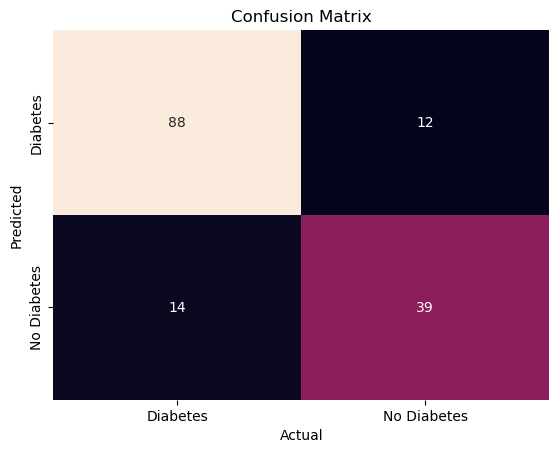

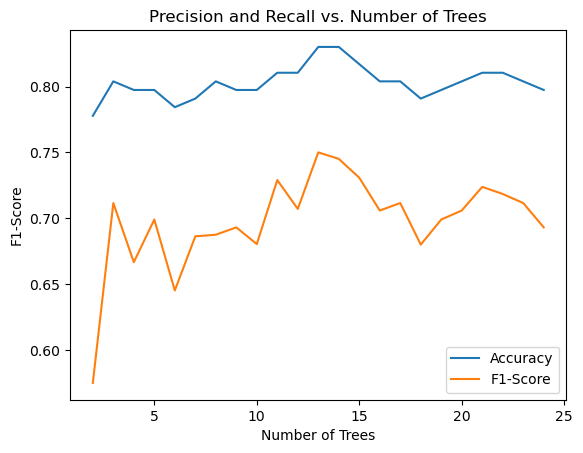

In [5]:
model = BaggingClassifier(random_state = 20)
model.fit(X_train,y_train)
y_pred = model.predict(X_test)

print("Default Model Performance metrics are as below :-\n")
print("Accuracy is ",accuracy_score(y_test,y_pred))
print("Precision is ",precision_score(y_test,y_pred))
print("Recall is ",recall_score(y_test,y_pred))
print("F1-Score is ",f1_score(y_test,y_pred))

f = 0
n = 0
df = pd.DataFrame(columns = ['n','f1-score','accuracy'])
for i in range(2,25):
    model = BaggingClassifier(n_estimators=i, random_state = 20)
    model.fit(X_train,y_train)
    y_pred = model.predict(X_test)
    df = pd.concat([pd.DataFrame([[i, f1_score(y_test,y_pred), accuracy_score(y_test,y_pred)]], columns=df.columns), df], ignore_index=True)
    if f1_score(y_test,y_pred) > f:
        f = f1_score(y_test,y_pred)
        j = i

model = BaggingClassifier(n_estimators=j, random_state = 20)
model.fit(X_train,y_train)
y_pred = model.predict(X_test)

print("\nBest Model Performance metrics for ",j," as n estimater are as below :-")
print("Accuracy is ",accuracy_score(y_test,y_pred))
print("Precision is ",precision_score(y_test,y_pred))
print("Recall is ",recall_score(y_test,y_pred))
print("F1-Score is ",f1_score(y_test,y_pred))

cm = confusion_matrix(y_test,y_pred)
print(cm)
ax = plt.subplot()
sns.heatmap(cm,annot = True , fmt = "d" , cbar = False , ax = ax)
ax.set_xlabel('Actual')
ax.set_ylabel('Predicted')
ax.set_title('Confusion Matrix')
ax.xaxis.set_ticklabels(['Diabetes','No Diabetes'])
ax.yaxis.set_ticklabels(['Diabetes','No Diabetes'])
plt.show()


# Plotting precision and recall scores against Max Leaf Nodes
plt.plot( df["n"],df["accuracy"], label='Accuracy')
plt.plot( df["n"], df["f1-score"], label='F1-Score')
plt.xlabel('Number of Trees')
plt.ylabel('F1-Score')
plt.title('Precision and Recall vs. Number of Trees')
plt.legend()
plt.show()

* Use Random Forest algorithm to classify Outcome and print the default model performance metrics: Accuracy, Precision, Recall, F1Score. Plot F1Score Accuracy against parameter: n_estimators with range of values from 2 to 25.

Default Model Performance metrics are as below :-

Accuracy is  0.7843137254901961
Precision is  0.7380952380952381
Recall is  0.5849056603773585
F1-Score is  0.6526315789473685

Best Model Performance metrics for  3  as n estimater are as below :-
Accuracy is  0.7973856209150327
Precision is  0.7391304347826086
Recall is  0.6415094339622641
F1-Score is  0.6868686868686867
[[88 12]
 [19 34]]


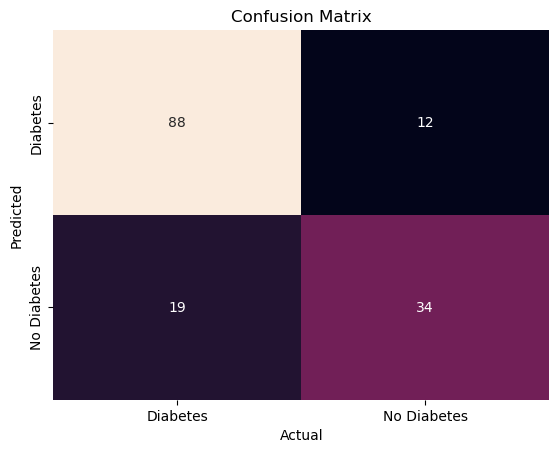

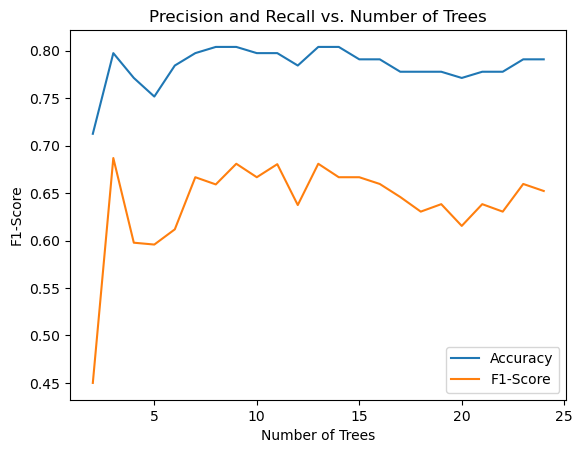

In [6]:
model = RandomForestClassifier(random_state = 20)
model.fit(X_train,y_train)
y_pred = model.predict(X_test)

print("Default Model Performance metrics are as below :-\n")
print("Accuracy is ",accuracy_score(y_test,y_pred))
print("Precision is ",precision_score(y_test,y_pred))
print("Recall is ",recall_score(y_test,y_pred))
print("F1-Score is ",f1_score(y_test,y_pred))

f = 0
n = 0
df = pd.DataFrame(columns = ['n','f1-score','accuracy'])
for i in range(2,25):
    model = RandomForestClassifier(n_estimators=i, random_state = 20)
    model.fit(X_train,y_train)
    y_pred = model.predict(X_test)
    df = pd.concat([pd.DataFrame([[i, f1_score(y_test,y_pred), accuracy_score(y_test,y_pred)]], columns=df.columns), df], ignore_index=True)
    if f1_score(y_test,y_pred) > f:
        f = f1_score(y_test,y_pred)
        j = i

model = RandomForestClassifier(n_estimators=j, random_state = 20)
model.fit(X_train,y_train)
y_pred = model.predict(X_test)

print("\nBest Model Performance metrics for ",j," as n estimater are as below :-")
print("Accuracy is ",accuracy_score(y_test,y_pred))
print("Precision is ",precision_score(y_test,y_pred))
print("Recall is ",recall_score(y_test,y_pred))
print("F1-Score is ",f1_score(y_test,y_pred))

cm = confusion_matrix(y_test,y_pred)
print(cm)
ax = plt.subplot()
sns.heatmap(cm,annot = True , fmt = "d" , cbar = False , ax = ax)
ax.set_xlabel('Actual')
ax.set_ylabel('Predicted')
ax.set_title('Confusion Matrix')
ax.xaxis.set_ticklabels(['Diabetes','No Diabetes'])
ax.yaxis.set_ticklabels(['Diabetes','No Diabetes'])
plt.show()


# Plotting f1 and accuracy scores against n-estimator
plt.plot( df["n"],df["accuracy"], label='Accuracy')
plt.plot( df["n"], df["f1-score"], label='F1-Score')
plt.xlabel('Number of Trees')
plt.ylabel('F1-Score')
plt.title('Precision and Recall vs. Number of Trees')
plt.legend()
plt.show()

* Use Adaboost algorithm on Decision trees to classify Outcome and print the default model performance metrics: Accuracy, Precision, Recall, F1Score.

Default Model Performance metrics are as below :-

Accuracy is  0.7843137254901961
Precision is  0.75
Recall is  0.5660377358490566
F1-Score is  0.6451612903225807

Best Model Performance metrics for  19  as n estimater are as below :-
Accuracy is  0.8300653594771242
Precision is  0.8292682926829268
Recall is  0.6415094339622641
F1-Score is  0.723404255319149
[[93  7]
 [19 34]]


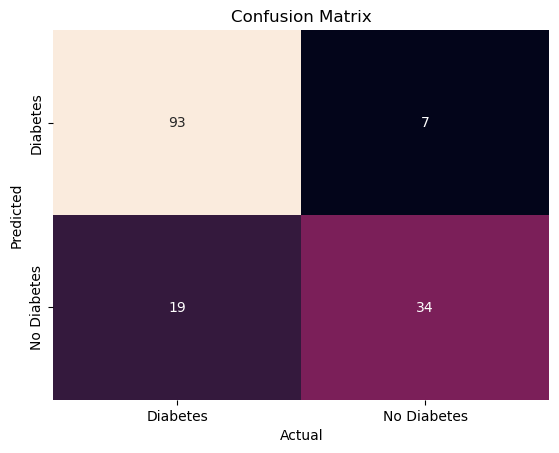

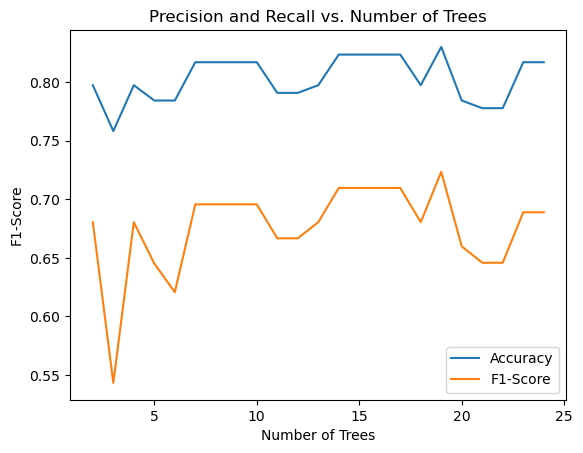

In [7]:
model = AdaBoostClassifier()
model.fit(X_train,y_train)
y_pred = model.predict(X_test)

print("Default Model Performance metrics are as below :-\n")
print("Accuracy is ",accuracy_score(y_test,y_pred))
print("Precision is ",precision_score(y_test,y_pred))
print("Recall is ",recall_score(y_test,y_pred))
print("F1-Score is ",f1_score(y_test,y_pred))

f = 0
n = 0
df = pd.DataFrame(columns = ['n','f1-score','accuracy'])
for i in range(2,25):
    model = AdaBoostClassifier(n_estimators=i, random_state = 20)
    model.fit(X_train,y_train)
    y_pred = model.predict(X_test)
    df = pd.concat([pd.DataFrame([[i, f1_score(y_test,y_pred), accuracy_score(y_test,y_pred)]], columns=df.columns), df], ignore_index=True)
    if f1_score(y_test,y_pred) > f:
        f = f1_score(y_test,y_pred)
        j = i

model = AdaBoostClassifier(n_estimators=j, random_state = 20)
model.fit(X_train,y_train)
y_pred = model.predict(X_test)

print("\nBest Model Performance metrics for ",j," as n estimater are as below :-")
print("Accuracy is ",accuracy_score(y_test,y_pred))
print("Precision is ",precision_score(y_test,y_pred))
print("Recall is ",recall_score(y_test,y_pred))
print("F1-Score is ",f1_score(y_test,y_pred))

cm = confusion_matrix(y_test,y_pred)
print(cm)
ax = plt.subplot()
sns.heatmap(cm,annot = True , fmt = "d" , cbar = False , ax = ax)
ax.set_xlabel('Actual')
ax.set_ylabel('Predicted')
ax.set_title('Confusion Matrix')
ax.xaxis.set_ticklabels(['Diabetes','No Diabetes'])
ax.yaxis.set_ticklabels(['Diabetes','No Diabetes'])
plt.show()


# Plotting f1 and accuracy scores against n-estimator
plt.plot( df["n"],df["accuracy"], label='Accuracy')
plt.plot( df["n"], df["f1-score"], label='F1-Score')
plt.xlabel('Number of Trees')
plt.ylabel('F1-Score')
plt.title('Precision and Recall vs. Number of Trees')
plt.legend()
plt.show()

In [9]:
x = pd.read_csv("classification.csv")
x

,model,accuracy,precision,recall,f1-score
0,Simple Logistic Regression,0.725225,0.544000,0.944444,0.690355
1,k Neighbour (manhattan),0.847826,0.879310,0.645570,0.744526
2,SVM,0.648649,0.727273,0.767196,0.685714
3,Dicision Tree Classifier,0.836601,0.759259,0.773585,0.766355
4,Bagging Classifier,0.830065,0.764706,0.735849,0.750000
5,Random Forest Classifier,0.797386,0.739130,0.641509,0.686869
6,Ada Boost Classifier,0.830065,0.829268,0.641509,0.723404


Name - Nikhil Khatri

SIC  - 21BCSA92